<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Haybarn](https://query.farm/products/haybarn/) · [Guide](README.md)

# 02 · From a funding comparison to an order-size question

A funding difference raises a practical question: **how much exposure could change
hands at the displayed prices?** Choose an order size, compare the quantity behind
the best quotes, and walk a deeper book. Then put that snapshot beside hourly
prices and executed trades. A final leverage scenario makes the boundary between
observations and assumptions explicit.

This BTC walkthrough runs independently. Books, marks and trades are separate
snapshots; their timestamps and coverage matter when interpreting the result.

## Choose the run

`ORDER_USD` controls the reference line and the center of the fill comparison.
The other sizes are multiples of it. Replay candle dates may be narrowed within
**12 Nov 18:00 → 13 Nov 00:00 UTC**; trade dates within **13 Nov 01:00 → 01:01 UTC**,
all in 2026. Ends are exclusive. Live defaults use the last six complete hours and
the most recent complete minute. BTC contracts are discovered from the worker.

Edit the visible parameters, then **Restart Kernel → Run All**. Saved outputs are a replay run.
`DATA_MODE = "live"` uses public APIs with recent default dates; there is no fallback to fixtures.
[Setup instructions](README.md#run-in-vs-code) are separate from the analysis.

The visible connection SQL downloads the pinned **v0.1.5** worker through `uvx`. No local worker build or path configuration is needed. The selected data mode configures its fixture and clock environment before connection.


In [1]:
DATA_MODE = "replay"
ORDER_USD = 100_000
ORDER_MULTIPLIERS = (0.1, 1, 10, 1000)
START_DATE = None             # Candle analysis start, inclusive UTC
END_DATE = None               # Candle analysis end, exclusive UTC
TRADE_START = None
TRADE_END = None
TRADE_BUCKET_SECONDS = 5

In [2]:
# Python setup · expand to inspect environment and shared presentation helpers.
from pathlib import Path
import os
import sys
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file() and (p / "fixtures/venues").is_dir()
)
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from notebook_support import (
    ASK, BID, COLORS, VENUE_NAMES, finite_numbers, finish_chart, make_run,
    money, number, prose, require_rows, set_theme, sql_text,
)
run = make_run(DATA_MODE, NOTEBOOK_DIR)
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

def chart(fig, title, subtitle, source=None):
    finish_chart(fig, title, subtitle, source or run.source)

Tip: You may define configurations in /Users/rusty/Development/vgi-perps/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-perps/notebooks/pyproject.toml.

In [3]:
order_usd = finite_numbers([ORDER_USD], "ORDER_USD", positive=True)[0]
multipliers = finite_numbers(ORDER_MULTIPLIERS, "ORDER_MULTIPLIERS", positive=True)
order_sizes = finite_numbers([order_usd, *(order_usd*m for m in multipliers)], "order sizes", positive=True)
if not isinstance(TRADE_BUCKET_SECONDS, int) or not 1 <= TRADE_BUCKET_SECONDS <= 60:
    raise ValueError("TRADE_BUCKET_SECONDS must be an integer from 1 through 60.")
candle_window = run.window("candles", START_DATE, END_DATE)
trade_window = run.window("trades", TRADE_START, TRADE_END)
run.badge(candles=candle_window, trades=trade_window)
prose(f"Reference order: **{money(order_usd)}**. Comparison sizes: " + ", ".join(money(v) for v in order_sizes) + ".")

**REPLAY · local recorded responses**  
Recorded worker clock: **2026-11-13 01:20:00 UTC**. Venue requests stay local.  
**Candles:** 12 Nov 2026 18:00 → 13 Nov 2026 00:00 UTC (end excluded)  
**Trades:** 13 Nov 2026 01:00 → 13 Nov 2026 01:01 UTC (end excluded)

Reference order: **\$100,000**. Comparison sizes: \$10,000, \$100,000, \$1,000,000, \$100,000,000.

In [4]:
%%sql
-- uvx fetches the pinned worker release; no local worker installation is needed.
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'perps' (TYPE vgi, LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-perps@v0.1.5 vgi-perps-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Locate the contracts before looking at prices

A ticker is not always a contract identifier. Discover the BTC instruments, retain
their contract sizes and quote currencies, and inspect venue availability. This
walkthrough uses Kalshi, Coinbase and Hyperliquid; it stops with a diagnostic if a
required contract is unavailable. Missing venue data must not look like zero liquidity.

In [5]:
%%sql
SELECT venue, status, last_error FROM perps.main.venues() ORDER BY venue;

,venue,status,last_error
0,binance,error,VenueError: binance (ccxt binanceusdm) fetch_m...
1,bitnomial,ok,None
2,bybit,error,VenueError: bybit (ccxt bybit) fetch_markets f...
3,coinbase,ok,None
4,hyperliquid,ok,None
5,kalshi,ok,None
6,og,ok,None


In [6]:
%%sql contracts <<
SELECT venue, symbol, contract_size, quote_ccy FROM perps.main.instruments(underlying := 'BTC')
WHERE venue IN ('kalshi', 'coinbase', 'hyperliquid') ORDER BY venue, symbol;

In [7]:
display(contracts)
symbols = {}
for venue in ("kalshi", "coinbase", "hyperliquid"):
    available = contracts[contracts.venue.eq(venue)]
    require_rows(available, f"{venue} BTC contracts")
    symbols[venue] = available.iloc[0].symbol
prose("Selected contracts: " + "; ".join(f"**{VENUE_NAMES[v]} / {s}**" for v,s in symbols.items()) +
      ". When a venue returns multiple BTC contracts, this walkthrough selects the first symbol alphabetically.")

,venue,symbol,contract_size,quote_ccy
0,coinbase,BIP-20DEC30-CDE,0.0100,USD
1,hyperliquid,BTC,1.0000,USDC
2,kalshi,KXBTCPERP,0.0001,USD


Selected contracts: **Kalshi / KXBTCPERP**; **Coinbase / BIP-20DEC30-CDE**; **Hyperliquid / BTC**. When a venue returns multiple BTC contracts, this walkthrough selects the first symbol alphabetically.

## Start with the quantity behind the best price

A tight spread describes the first price level. The quantity behind it can be
very different. `order_book()` converts native contracts to base units and
cumulative notional, letting us compare amounts as well as prices.

Fetch five levels per side. Panels share a notional scale but have independent
price-distance scales. Hyperliquid's USD-labelled field retains the USDC quote;
no currency conversion is applied. The dashed line follows your chosen order size.

In [8]:
%%sql
CREATE OR REPLACE TABLE books AS
{% for venue, symbol in symbols.items() %}
SELECT * FROM perps.main.order_book({{ sql_text(venue) }}, {{ sql_text(symbol) }}, depth := 5)
{% if not loop.last %}UNION ALL{% endif %}
{% endfor %};
SELECT venue, side, level, price, size_contracts, size_base, round(cum_usd, 2) AS cumulative_usd
FROM books WHERE level <= 2 ORDER BY venue, side, level;

,venue,side,level,price,size_contracts,size_base,cumulative_usd
0,coinbase,ask,1,70885.0,3.00000,0.03000,2126.55
1,coinbase,ask,2,70890.0,491.00000,4.91000,350196.45
2,coinbase,bid,1,70875.0,1.00000,0.01000,708.75
3,coinbase,bid,2,70870.0,346.00000,3.46000,245918.95
4,hyperliquid,ask,1,70939.0,0.00741,0.00741,525.66
5,hyperliquid,ask,2,70941.0,0.01286,0.01286,1437.96
6,hyperliquid,bid,1,70938.0,5.20020,5.20020,368891.79
7,hyperliquid,bid,2,70937.0,0.11277,0.11277,376891.35
8,kalshi,ask,1,70884.0,150.00000,0.01500,1063.26
9,kalshi,ask,2,70885.0,432.00000,0.04320,4125.49


In [9]:
%%sql book_plot <<
WITH tops AS (
    SELECT venue, (max(price) FILTER (WHERE side = 'bid')
                + min(price) FILTER (WHERE side = 'ask')) / 2 AS mid
    FROM books GROUP BY venue
)
SELECT b.*, (price / mid - 1) * 10000 AS distance_bps, cum_usd / 1000 AS cumulative_thousands
FROM books b JOIN tops USING (venue) ORDER BY venue, side, level;

findfont: Failed to find font weight semibold for Arial, now using 700.


findfont: Failed to find font weight semibold for Arial, now using 700.


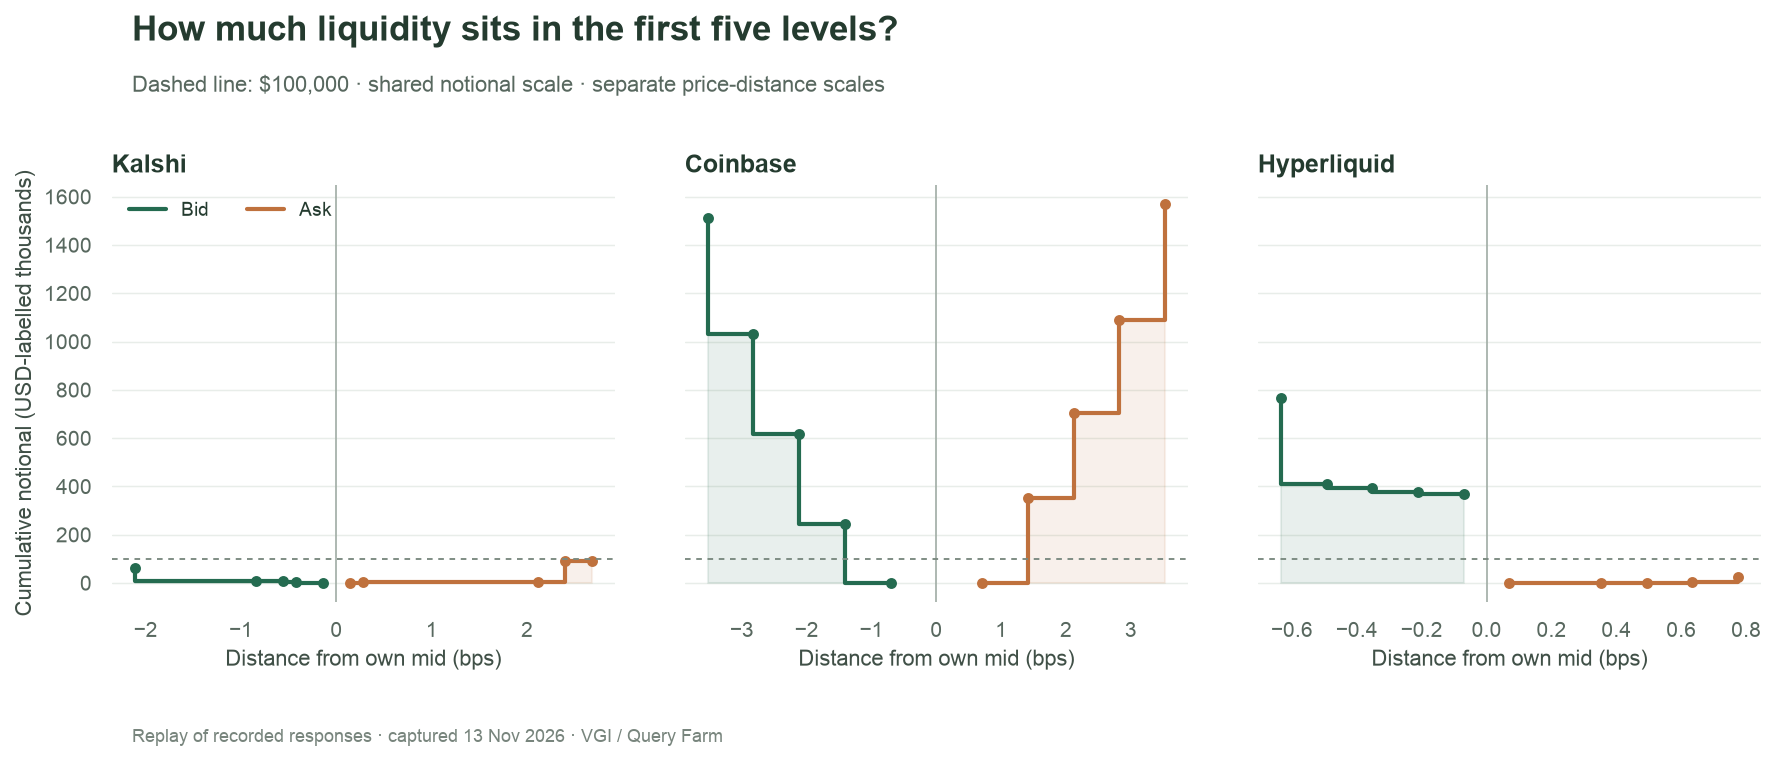

In [10]:
require_rows(book_plot, "order-book levels")
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True)
for ax, venue in zip(axes, symbols):
    for side, color in [("bid", BID), ("ask", ASK)]:
        rows = book_plot[(book_plot.venue == venue) & (book_plot.side == side)].sort_values("distance_bps")
        where = "pre" if side == "bid" else "post"
        ax.step(rows.distance_bps, rows.cumulative_thousands, where=where, color=color, label=side.title())
        ax.fill_between(rows.distance_bps, rows.cumulative_thousands, step=where, color=color, alpha=0.1)
        ax.scatter(rows.distance_bps, rows.cumulative_thousands, color=color, s=18)
    ax.axvline(0, color="#A0ACA4", linewidth=0.8)
    ax.axhline(order_usd/1000, color="#7A8980", linestyle=(0, (3, 3)), linewidth=0.9)
    ax.set(title=VENUE_NAMES[venue], xlabel="Distance from own mid (bps)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Cumulative notional (USD-labelled thousands)")
axes[0].legend(loc="upper left", ncol=2, fontsize=9)
chart(fig, "How much liquidity sits in the first five levels?",
      f"Dashed line: ${order_usd:,.0f} · shared notional scale · separate price-distance scales")
assert (book_plot.sort_values("level").groupby(["venue", "side"]).cum_usd.diff().dropna() >= -1e-8).all()

In [11]:
asks = book_plot[(book_plot.venue == "kalshi") & (book_plot.side == "ask")]
if not asks.empty:
    capacity = asks.cum_usd.max()
    relation = "below" if capacity < order_usd else "at or above"
    prose(f"The displayed Kalshi ask levels contain **{money(capacity)}**, {relation} the **{money(order_usd)}** reference order. "
          "A five-level slice is not a full capacity assessment. The next query asks for a deeper book.")

The displayed Kalshi ask levels contain **\$91,198**, below the **\$100,000** reference order. A five-level slice is not a full capacity assessment. The next query asks for a deeper book.

## Walk the book at the size we care about

`depth_metrics()` reports the average fill price's distance from mid, filled
notional, and whether both sides fill completely. We request 200 levels and compare
your order with smaller and larger multiples. Costs apply to the filled portion
and exclude fees or a market response.

In replay, all size scenarios reuse the same deeper recording, which differs from
the five-level recording. Live calls may observe different books, so a live
comparison can reflect both size and market movement.

In [12]:
%%sql fills <<
CREATE OR REPLACE TABLE fill_scenarios AS
{% for amount in order_sizes %}
SELECT * FROM perps.main.depth_metrics('kalshi', {{ sql_text(symbols['kalshi']) }},
    notional_usd := {{ amount }}, depth := 200)
{% if not loop.last %}UNION ALL{% endif %}
{% endfor %};
SELECT notional_usd, buy_cost_bps, sell_cost_bps, fully_filled,
       100 * buy_filled_usd / notional_usd AS buy_fill_pct,
       100 * sell_filled_usd / notional_usd AS sell_fill_pct
FROM fill_scenarios ORDER BY notional_usd;

,notional_usd,buy_cost_bps,sell_cost_bps,fully_filled,buy_fill_pct,sell_fill_pct
0,1.00000e+04,1.77084,1.24727,True,100.0000,100.00000
1,1.00000e+05,2.58094,1.96613,True,100.0000,100.00000
2,1.00000e+06,3.56662,2.39265,True,100.0000,100.00000
3,1.00000e+08,25.40721,23.69830,False,10.8914,14.51092


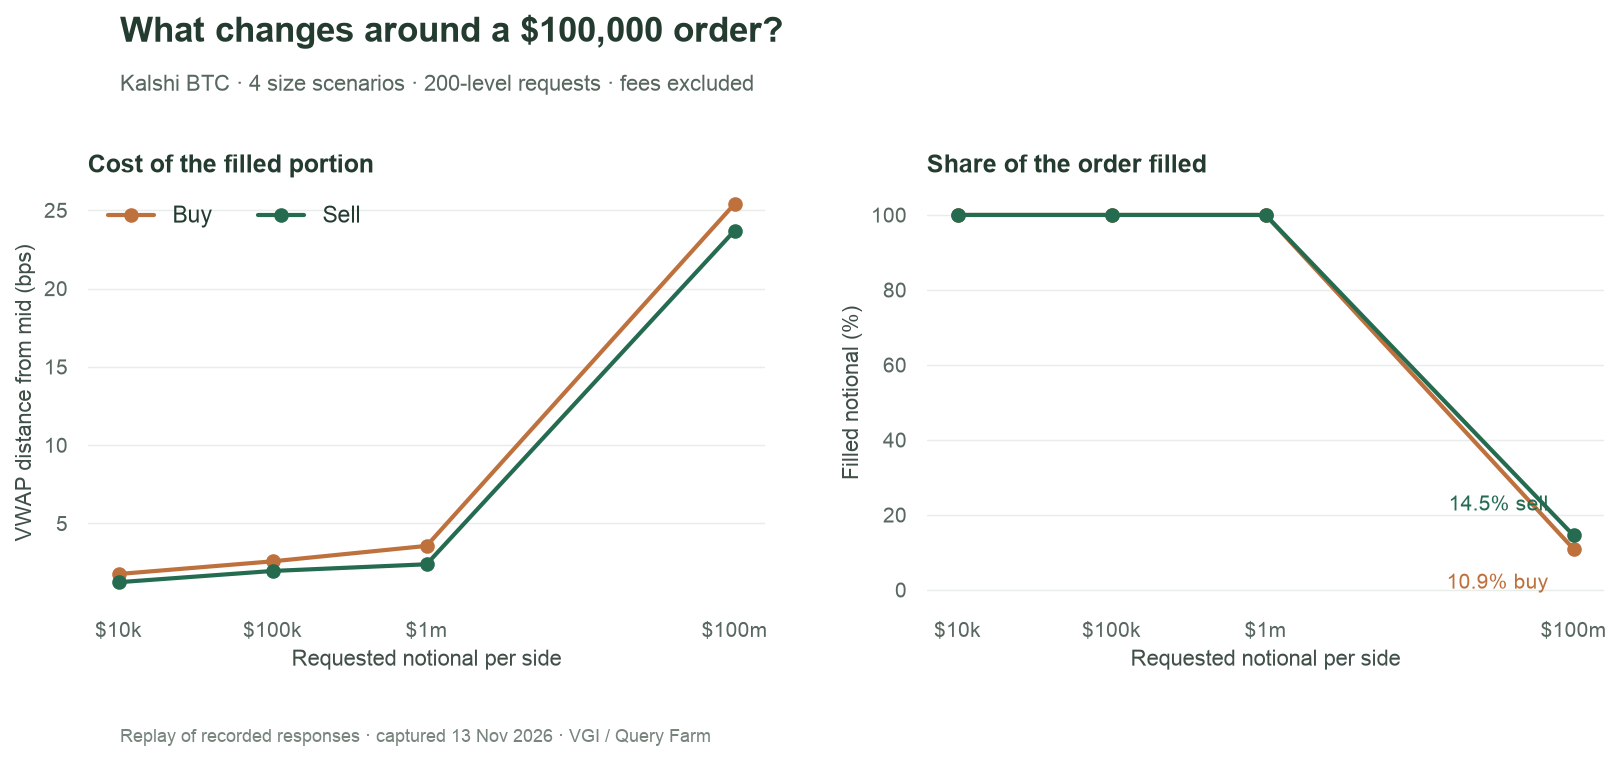

In [13]:
display(fills)
require_rows(fills, "fill scenarios")
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for side, color in [("buy", ASK), ("sell", BID)]:
    axes[0].plot(fills.notional_usd, fills[f"{side}_cost_bps"], "o-", color=color, label=side.title(), markersize=6)
    axes[1].plot(fills.notional_usd, fills[f"{side}_fill_pct"], "o-", color=color, label=side.title(), markersize=6)
    last = fills.iloc[-1]
    axes[1].annotate(f"{last[f'{side}_fill_pct']:.1f}% {side}",
        (last.notional_usd, last[f"{side}_fill_pct"]), xytext=(-12, -19 if side == "buy" else 12),
        textcoords="offset points", ha="right", color=color, fontsize=10)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(fills.notional_usd)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1e6:g}m" if x>=1e6 else f"${x/1e3:g}k"))
    ax.set_xlabel("Requested notional per side")
    ax.grid(axis="x", visible=False)
axes[0].set(title="Cost of the filled portion", ylabel="VWAP distance from mid (bps)")
axes[0].legend(loc="upper left", ncol=2)
axes[1].set(title="Share of the order filled", ylabel="Filled notional (%)", ylim=(-3, 108))
chart(fig, f"What changes around a ${order_usd:,.0f} order?",
      f"Kalshi BTC · {len(fills)} size scenarios · 200-level requests · fees excluded")
assert fills.buy_fill_pct.between(-1e-8, 100+1e-8).all()
assert fills.sell_fill_pct.between(-1e-8, 100+1e-8).all()

In [14]:
selected = fills.loc[fills.notional_usd.eq(order_usd)].iloc[0]
status = "fills completely on both sides" if selected.fully_filled else "does not fill completely on both sides"
prose(f"The **{money(order_usd)}** scenario **{status}**. Its filled portion costs "
      f"**{number(selected.buy_cost_bps)} bps to buy** and **{number(selected.sell_cost_bps)} bps to sell** from mid. "
      f"Filled shares are **{selected.buy_fill_pct:.1f}% buy** and **{selected.sell_fill_pct:.1f}% sell**. "
      f"Across the {len(fills)} scenarios, {int((~fills.fully_filled).sum())} cannot fill completely. "
      "A partial fill's cost is not a quote for the whole requested order.")

The **\$100,000** scenario **fills completely on both sides**. Its filled portion costs **2.58 bps to buy** and **1.97 bps to sell** from mid. Filled shares are **100.0% buy** and **100.0% sell**. Across the 4 scenarios, 1 cannot fill completely. A partial fill's cost is not a quote for the whole requested order.

## Put that capacity in a moving market

The fill calculation holds each book still. Hourly candles add the price path
around that snapshot, while the volume panel asks a separate coverage question.
We filter bar starts to your selected half-open interval: some APIs return an
extra bar at the end. Missing dollar turnover remains missing; contract counts
alone cannot establish a comparable dollar-volume ranking.

In [15]:
%%sql candles <<
CREATE OR REPLACE TABLE hourly AS
{% for venue in ['kalshi', 'coinbase'] %}
SELECT * FROM perps.main.candles({{ sql_text(venue) }}, {{ sql_text(symbols[venue]) }},
    start_date := TIMESTAMPTZ {{ sql_text(candle_window.fetch_start) }},
    end_date := TIMESTAMPTZ {{ sql_text(candle_window.fetch_end) }}, bar := '1h')
{% if not loop.last %}UNION ALL{% endif %}
{% endfor %};
SELECT venue, ts, open, high, low, close, volume_usd / 1e6 AS volume_millions
FROM hourly WHERE ts >= TIMESTAMPTZ {{ sql_text(candle_window.start) }}
              AND ts < TIMESTAMPTZ {{ sql_text(candle_window.end) }} ORDER BY venue, ts;

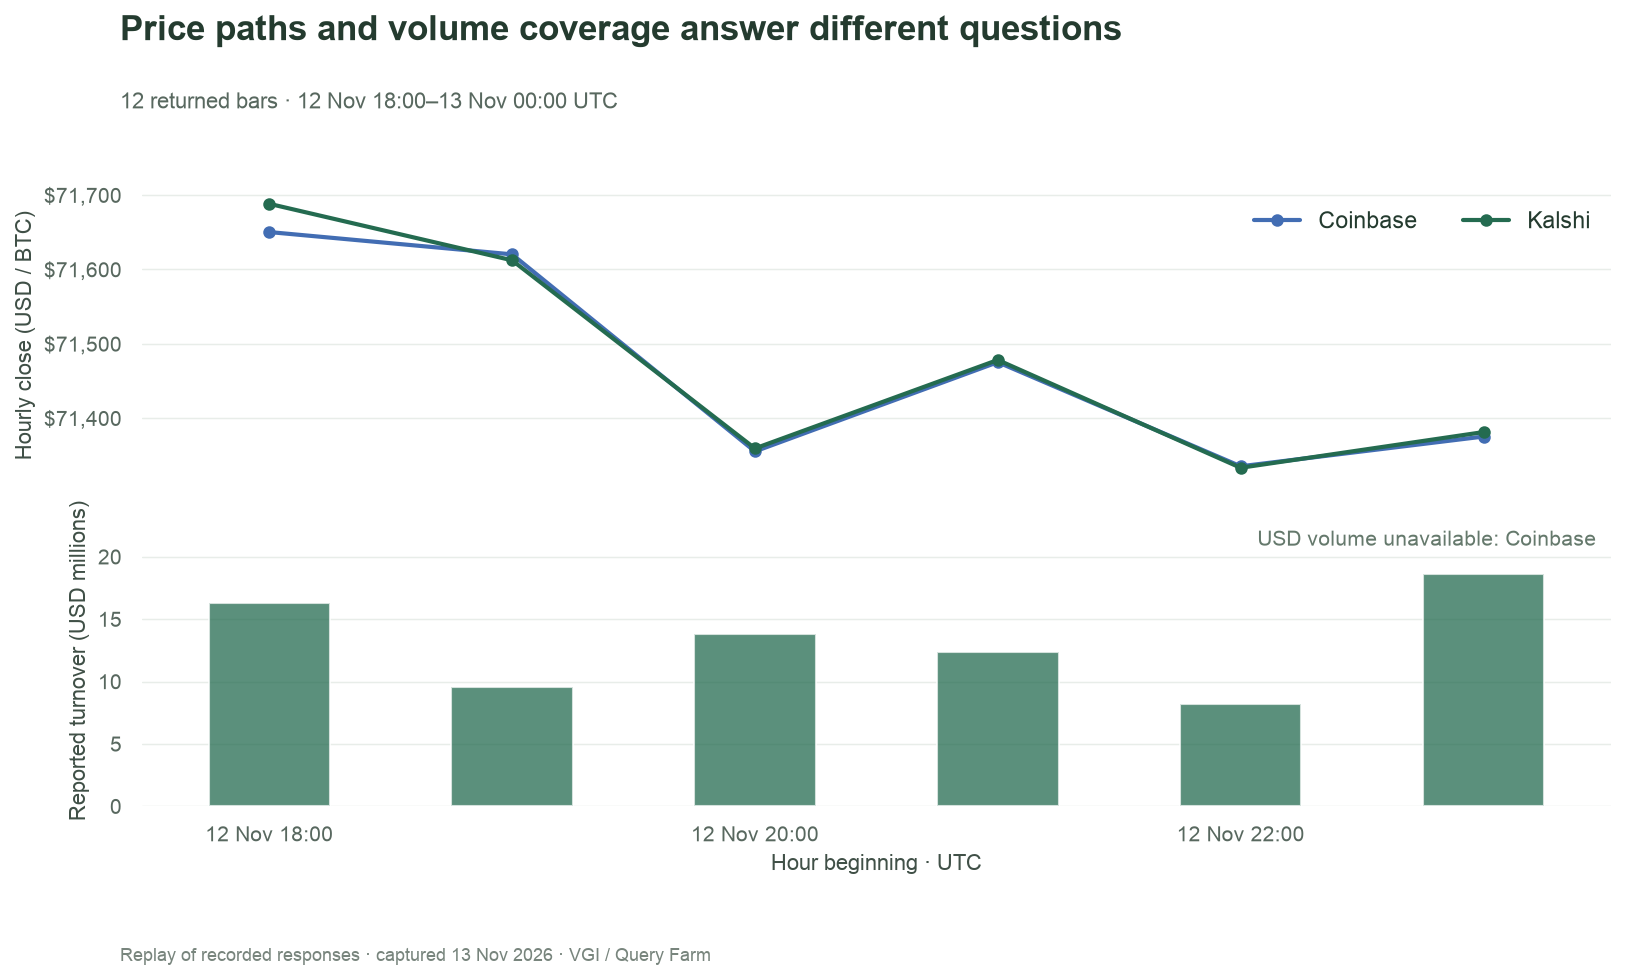

In [16]:
require_rows(candles, "candles in the selected window")
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
missing_volume = []
for venue, rows in candles.groupby("venue"):
    axes[0].plot(rows.ts, rows.close, "o-", color=COLORS[venue], markersize=5, label=VENUE_NAMES[venue])
    reported = rows.dropna(subset=["volume_millions"])
    if reported.empty: missing_volume.append(VENUE_NAMES[venue])
    axes[1].bar(reported.ts, reported.volume_millions, width=30/1440,
                color=COLORS[venue], alpha=0.75, label=VENUE_NAMES[venue])
axes[0].set(ylabel="Hourly close (USD / BTC)", xlabel="")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[0].legend(ncol=2, loc="upper right")
axes[1].set(ylabel="Reported turnover (USD millions)", xlabel="Hour beginning · UTC")
axes[1].margins(y=0.25)
if missing_volume:
    axes[1].text(0.99, 0.95, "USD volume unavailable: " + ", ".join(missing_volume),
                 transform=axes[1].transAxes, ha="right", va="top", color="#65796C", fontsize=10)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M", tz="UTC"))
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=6))
for ax in axes: ax.grid(axis="x", visible=False)
chart(fig, "Price paths and volume coverage answer different questions",
      f"{len(candles)} returned bars · {candle_window.start:%d %b %H:%M}–{candle_window.end:%d %b %H:%M} UTC")

In [17]:
for venue, rows in candles.groupby("venue"):
    first, last = rows.iloc[0], rows.iloc[-1]
    prose(f"**{VENUE_NAMES[venue]}** returns **{len(rows)} bars**: its close moves from **{money(first.close)}** "
          f"to **{money(last.close)}**. Dollar volume is available for **{rows.volume_millions.notna().sum()} of {len(rows)}** bars.")
prose("Unavailable volume is not zero trading. These observations put the depth snapshot in context; they do not explain its cause.")

**Coinbase** returns **6 bars**: its close moves from **\$71,650** to **\$71,375**. Dollar volume is available for **0 of 6** bars.

**Kalshi** returns **6 bars**: its close moves from **\$71,688** to **\$71,381**. Dollar volume is available for **6 of 6** bars.

Unavailable volume is not zero trading. These observations put the depth snapshot in context; they do not explain its cause.

## Zoom from bars to executed trades

Retrieve Kalshi prints, then aggregate them into your chosen number of seconds.
The worker handles pagination; the summary checks identifiers. Unknown taker sides
remain explicit and, when present, receive their own unsigned bars. Signed buy/sell
bars describe the initiator, not a change in total outstanding exposure.

In [18]:
%%sql trade_summary <<
CREATE OR REPLACE TABLE source_prints AS
SELECT * FROM perps.main.trades('kalshi', {{ sql_text(symbols['kalshi']) }},
    start_date := TIMESTAMPTZ {{ sql_text(trade_window.fetch_start) }},
    end_date := TIMESTAMPTZ {{ sql_text(trade_window.fetch_end) }});
CREATE OR REPLACE TABLE prints AS SELECT * FROM source_prints
WHERE ts >= TIMESTAMPTZ {{ sql_text(trade_window.start) }}
  AND ts < TIMESTAMPTZ {{ sql_text(trade_window.end) }};
SELECT count(*) AS trades, count(DISTINCT trade_id) AS distinct_trade_ids,
       sum(size_usd) AS traded_usd,
       count(*) FILTER (WHERE taker_side IS NULL OR taker_side NOT IN ('buy', 'sell')) AS unknown_taker_side
FROM prints;

In [19]:
%%sql flow <<
SELECT time_bucket(INTERVAL '{{ TRADE_BUCKET_SECONDS }} seconds', ts) AS bucket,
       coalesce(sum(size_usd) FILTER (WHERE taker_side = 'buy'), 0) AS buy_usd,
       coalesce(sum(size_usd) FILTER (WHERE taker_side = 'sell'), 0) AS sell_usd,
       coalesce(sum(size_usd) FILTER (WHERE taker_side IS NULL OR taker_side NOT IN ('buy', 'sell')), 0) AS unknown_usd,
       sum(price * size_contracts) / nullif(sum(size_contracts), 0) AS vwap
FROM prints GROUP BY bucket ORDER BY bucket;

,trades,distinct_trade_ids,traded_usd,unknown_taker_side
0,139,139,184237.2543,0


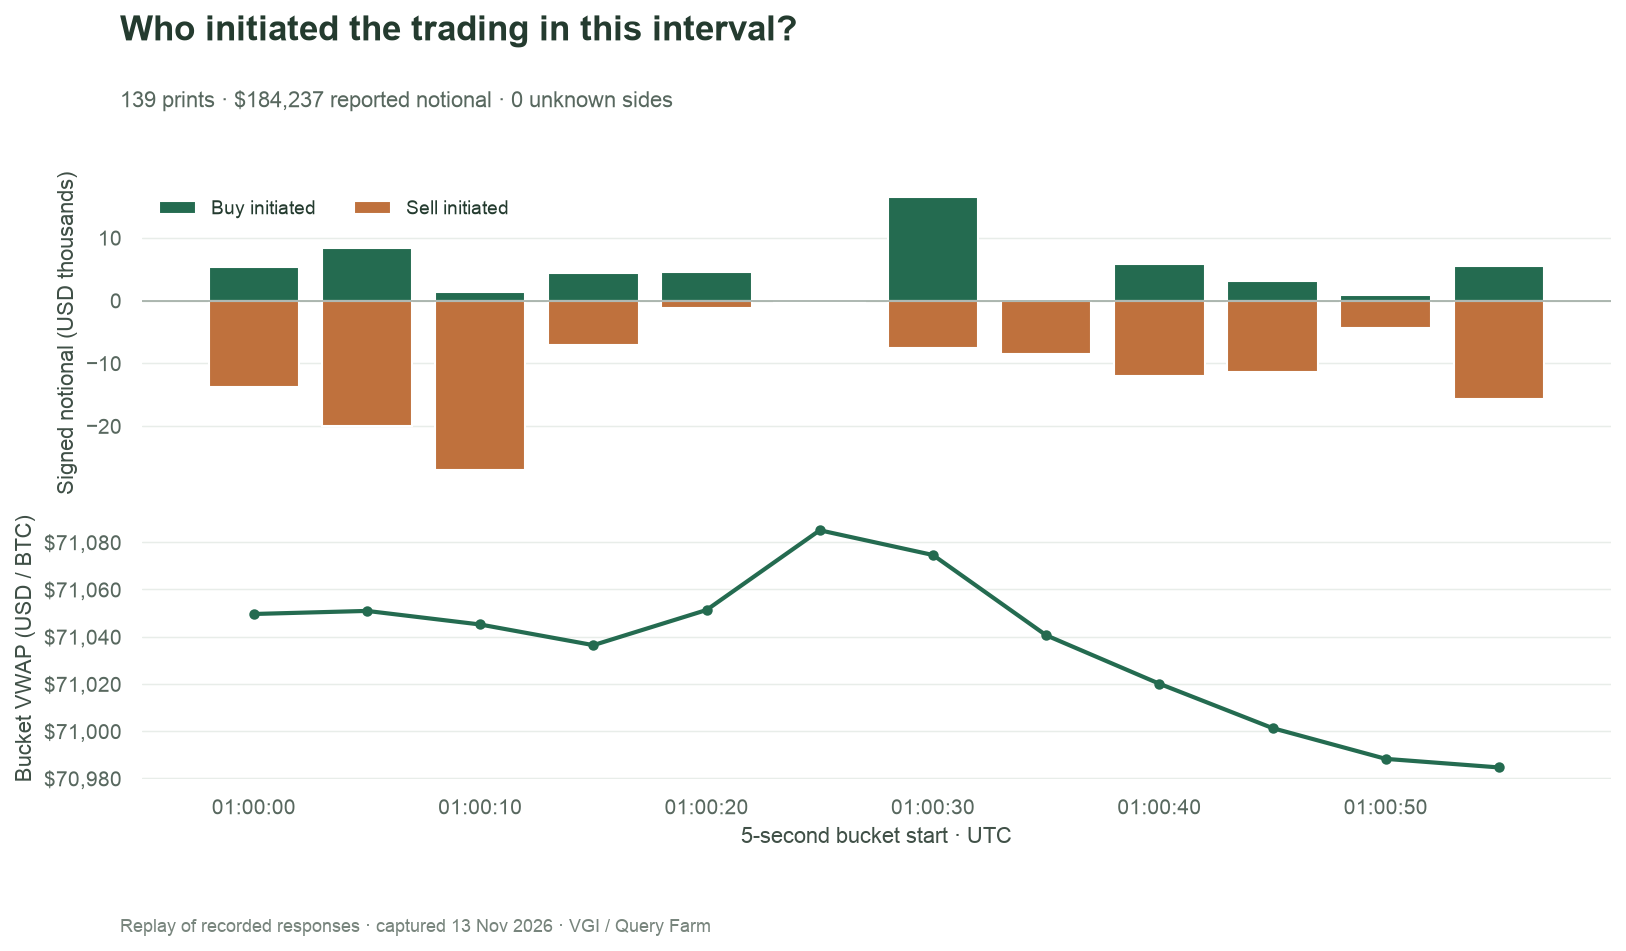

In [20]:
display(trade_summary)
stats = trade_summary.iloc[0]
assert stats.trades == stats.distinct_trade_ids, "Duplicate or missing trade IDs; inspect pagination."
if flow.empty:
    prose("No prints were returned for the selected interval. A trade-flow chart is unavailable.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.3), sharex=True,
                             gridspec_kw={"height_ratios": [1.15, 1]})
    width = TRADE_BUCKET_SECONDS*0.8/86400
    axes[0].bar(flow.bucket, flow.buy_usd/1000, width=width, color=BID, label="Buy initiated")
    axes[0].bar(flow.bucket, -flow.sell_usd/1000, width=width, color=ASK, label="Sell initiated")
    if flow.unknown_usd.gt(0).any():
        axes[0].bar(flow.bucket, flow.unknown_usd/1000, bottom=flow.buy_usd/1000,
                    width=width, color="#9A9A9A", label="Unknown side (unsigned)")
    axes[0].axhline(0, color="#A0ACA4", linewidth=0.8)
    axes[0].set_ylabel("Signed notional (USD thousands)")
    axes[0].legend(ncol=3, loc="upper left", fontsize=9)
    axes[1].plot(flow.bucket, flow.vwap, "o-", color=COLORS["kalshi"], markersize=4)
    axes[1].set(ylabel="Bucket VWAP (USD / BTC)", xlabel=f"{TRADE_BUCKET_SECONDS}-second bucket start · UTC")
    axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz="UTC"))
    for ax in axes: ax.grid(axis="x", visible=False)
    chart(fig, "Who initiated the trading in this interval?",
          f"{int(stats.trades)} prints · ${stats.traded_usd:,.0f} reported notional · {int(stats.unknown_taker_side)} unknown sides")

In [21]:
if not flow.empty:
    buys, sells = flow.buy_usd.sum(), flow.sell_usd.sum()
    relation = "Sell-initiated" if sells > buys else "Buy-initiated" if buys > sells else "Equal buy- and sell-initiated"
    prose(f"This interval contains **{int(stats.trades)} distinct prints** and **{money(stats.traded_usd)}** of reported trading. "
          f"{relation} notional leads the known-side comparison: **{money(buys)} buys**, **{money(sells)} sells**, "
          f"and **{money(flow.unknown_usd.sum())} unknown**. Aggregation changes the view of the path; it cannot explain why prices moved.")

This interval contains **139 distinct prints** and **\$184,237** of reported trading. Sell-initiated notional leads the known-side comparison: **\$56,096 buys**, **\$128,141 sells**, and **\$0 unknown**. Aggregation changes the view of the path; it cannot explain why prices moved.

## A price move raises a different question: assumed leverage

We have examined resting orders and completed trades. To explore how leverage
could make positions sensitive to a price move, we now make an explicit modeling
choice: assign Hyperliquid open interest to an assumed set of leverage buckets.

`liquidation_estimate()` uses entry at the mark, isolated linear margin and the
supported maintenance-margin schedule. It excludes fees and accrued funding.
Keep `mm_source` and `estimate_method` in the result so the assumptions are visible.

The bubble sizes come from the assumed weights, not from discovered accounts.
Each side carries the full open interest; adding long and short notionals would
double-count contracts. The worker's USD-labelled values retain the USDC quote currency.

In [22]:
%%sql
CREATE OR REPLACE TABLE liquidation_scenario AS
SELECT * FROM perps.main.liquidation_estimate('hyperliquid', 'BTC');
SELECT side, leverage, weight, liquidation_price, distance_pct, feasible,
       maintenance_margin_rate, mm_source, estimate_method
FROM liquidation_scenario ORDER BY side, leverage;

,side,leverage,weight,liquidation_price,distance_pct,feasible,maintenance_margin_rate,mm_source,estimate_method
0,long,2.0,0.30,35917.97468,-49.36709,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
1,long,3.0,0.25,47890.63291,-32.48945,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
2,long,5.0,0.20,57468.75949,-18.98734,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
3,long,10.0,0.15,64652.35443,-8.86076,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
4,long,20.0,0.10,68244.15190,-3.79747,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
5,short,2.0,0.30,105093.33333,48.14815,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
6,short,3.0,0.25,93416.29630,31.68724,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
7,short,5.0,0.20,84074.66667,18.51852,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
8,short,10.0,0.15,77068.44444,8.64198,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1
9,short,20.0,0.10,73565.33333,3.70370,True,0.0125,hyperliquid docs: maintenance = half of initia...,isolated_linear_entry_at_mark_v1


In [23]:
%%sql bands <<
SELECT side, leverage, distance_pct, notional_usd / 1e6 AS assumed_notional_millions
FROM liquidation_scenario WHERE feasible ORDER BY side, leverage;

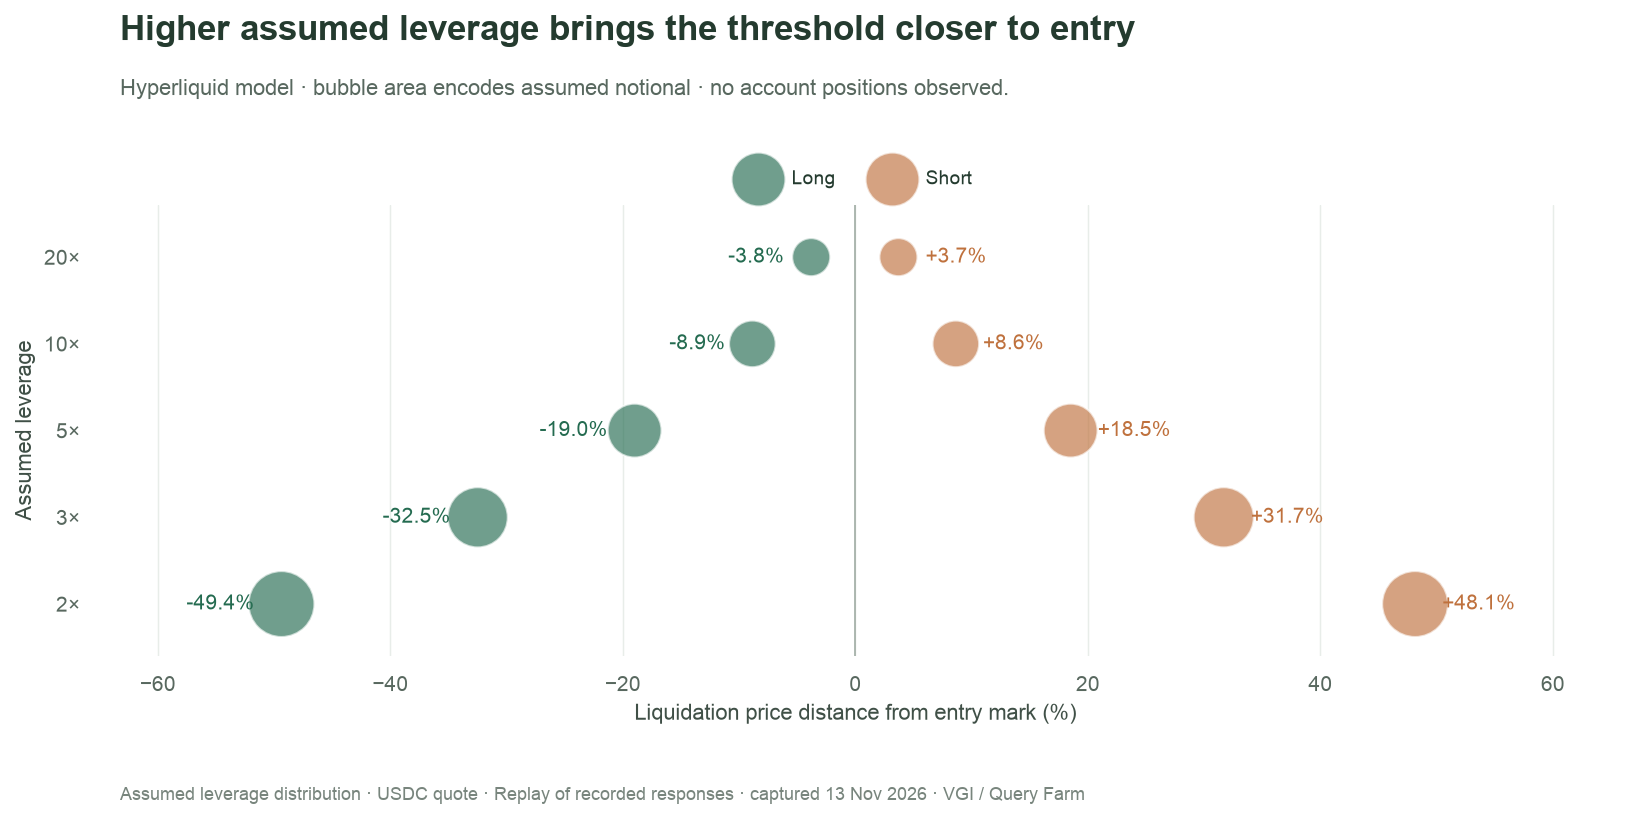

In [24]:
# Put leverage buckets on a readable category axis; bubble areas encode the assumption.
fig, ax = plt.subplots(figsize=(11, 5.4))
leverages = sorted(bands.leverage.unique())
for side, color in [("long", BID), ("short", ASK)]:
    rows = bands[bands.side == side]
    y = [leverages.index(v) for v in rows.leverage]
    ax.scatter(rows.distance_pct, y, s=rows.assumed_notional_millions / bands.assumed_notional_millions.max() * 1000,
               color=color, alpha=0.65, edgecolors="white", linewidths=1, label=side.title())
    for yi, row in zip(y, rows.itertuples()):
        ax.annotate(f"{row.distance_pct:+.1f}%", (row.distance_pct, yi),
                    xytext=(-13 if side == "long" else 13, 0), textcoords="offset points",
                    ha="right" if side == "long" else "left", va="center", fontsize=10, color=color)
ax.set_yticks(range(len(leverages)), [f"{v:g}×" for v in leverages])
ax.axvline(0, color="#A0ACA4", linewidth=0.8)
ax.set(xlabel="Liquidation price distance from entry mark (%)", ylabel="Assumed leverage", xlim=(-65, 65), ylim=(-0.6, 4.6))
ax.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.0), fontsize=9)
ax.grid(axis="y", visible=False)
chart(fig, "Higher assumed leverage brings the threshold closer to entry",
             "Hyperliquid model · bubble area encodes assumed notional · no account positions observed.",
             "Assumed leverage distribution · USDC quote · " + run.source)

In [25]:
longs = bands[bands.side.eq("long")].sort_values("leverage")
if not longs.empty:
    low, high = longs.iloc[0], longs.iloc[-1]
    prose(f"Under the model, the **{high.leverage:g}× long** reaches its threshold at **{high.distance_pct:+.1f}%** "
          f"from entry, compared with **{low.distance_pct:+.1f}%** for the **{low.leverage:g}× long**. "
          "Bubble sizes follow assumed weights; neither the weights nor the thresholds reveal actual accounts.")

Under the model, the **20× long** reaches its threshold at **-3.8%** from entry, compared with **-49.4%** for the **2× long**. Bubble sizes follow assumed weights; neither the weights nor the thresholds reveal actual accounts.

## Experiment: halve the reference order

Set `ORDER_USD = 50_000`, keep the other parameters fixed, and restart/run all.
**Predict first:** will the cost of each filled portion fall, and will the filled
share change? **Inspect:** the reference line, the selected-size callout and both
fill panels. Replay isolates size because it reuses the same recorded books; live
calls may also reflect a moving market. Restore `ORDER_USD = 100_000` afterward.

The key distinction is between available size, cost of what fills, and the context
around the snapshot. The final leverage model adds an explicit assumption, not
another observation of liquidity.

[All notebooks](README.md) · [SQL reference](https://github.com/Query-farm/vgi-perps#sql-surface) ·
[Venue mappings](https://github.com/Query-farm/vgi-perps/blob/main/docs/VENUES.md) · [Notebook standard](STANDARD.md)

The final collapsed cell releases this run's connection. Restart and run from the top after editing parameters.

In [26]:
# Cleanup · release the connection and worker
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>